In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense,
    Embedding, LSTM, Add, Dropout
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [ ]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Normalize to [0,1] and add a channel dimension: (N, 28, 28) -> (N, 28, 28, 1)
x_train = x_train.astype("float32")[..., np.newaxis] / 255.0
x_test = x_test.astype("float32")[..., np.newaxis] / 255.0

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
class_names = ["t-shirt", "trouser", "pullover", "dress", "coat",
               "sandal", "shirt", "sneaker", "bag", "ankle boot"]

TEMPLATES = [
    "a photo of a {}",
    "this picture shows a {}",
    "an image containing a {}",
    "a small picture of a {}",
    "here is a {}",
]

def make_caption(label_idx):
    name = class_names[label_idx]
    article_fix = "an " + name if name[0] in "aeiou" else "a " + name
    template = random.choice(TEMPLATES)
    return "startseq " + template.format(name).replace("a " + name, article_fix) + " endseq"

In [ ]:
N_TRAIN, N_TEST = 4000, 500
train_idx = np.random.choice(len(x_train), N_TRAIN, replace=False)
test_idx = np.random.choice(len(x_test), N_TEST, replace=False)

train_images = x_train[train_idx]
train_captions = [make_caption(int(y_train[i])) for i in train_idx]
test_images = x_test[test_idx]
test_captions = [make_caption(int(y_test[i])) for i in test_idx]

print("Example captions:", train_captions[:3])

Example captions: ['startseq a photo of a bag endseq', 'startseq a photo of a bag endseq', 'startseq an image containing a sneaker endseq']


In [ ]:
# 2. Tokenize captions and build the vocabulary

tokenizer = Tokenizer(oov_token="<unk>")
tokenizer.fit_on_texts(train_captions)
vocab_size = len(tokenizer.word_index) + 1
max_len = max(len(c.split()) for c in train_captions)
print(f"Vocab size: {vocab_size}, Max caption length: {max_len}")


def encode_captions(captions):
    return tokenizer.texts_to_sequences(captions)


train_seqs = encode_captions(train_captions)
test_seqs = encode_captions(test_captions)

Vocab size: 27, Max caption length: 9


In [ ]:
def build_sequences(images, seqs):
    X_img, X_seq, y = [], [], []
    for img, seq in zip(images, seqs):
        for t in range(1, len(seq)):
            in_seq, out_word = seq[:t], seq[t]
            in_seq = pad_sequences([in_seq], maxlen=max_len)[0]
            X_img.append(img)
            X_seq.append(in_seq)
            y.append(out_word)
    return np.array(X_img), np.array(X_seq), to_categorical(y, num_classes=vocab_size)


X_img_train, X_seq_train, y_train_cap = build_sequences(train_images, train_seqs)
print("Training pairs:", X_img_train.shape[0])

Training pairs: 24819


In [ ]:
EMBED_DIM = 128

image_input = Input(shape=(28, 28, 1), name="image_input")
cnn = Conv2D(32, (3, 3), activation="relu", padding="same")(image_input)
cnn = MaxPooling2D()(cnn)
cnn = Conv2D(64, (3, 3), activation="relu", padding="same")(cnn)
cnn = MaxPooling2D()(cnn)
cnn = GlobalAveragePooling2D()(cnn)
image_features = Dense(EMBED_DIM, activation="relu")(cnn)
image_features = Dropout(0.3)(image_features)

seq_input = Input(shape=(max_len,), name="caption_input")
seq_embed = Embedding(vocab_size, EMBED_DIM, mask_zero=True)(seq_input)
seq_embed = Dropout(0.3)(seq_embed)
seq_features = LSTM(EMBED_DIM)(seq_embed)

merged = Add()([image_features, seq_features])
merged = Dense(EMBED_DIM, activation="relu")(merged)
output = Dense(vocab_size, activation="softmax")(merged)

caption_model = Model(inputs=[image_input, seq_input], outputs=output)
caption_model.compile(optimizer="adam", loss="categorical_crossentropy",
                       metrics=["accuracy"])
caption_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 28, 28,    │        320 │ image_input[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 14, 14,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 14, 14,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 7, 7, 64)  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ caption_input       │ (None, 9)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ max_pooling2d_1[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 9, 128)    │      3,456 │ caption_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │      8,320 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 9, 128)    │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 9)         │          0 │ caption_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 128)       │    131,584 │ dropout_1[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128)       │          0 │ dropout[0][0],    │
│                     │                   │            │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     16,512 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 27)        │      3,483 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 182,171 (711.61 KB)

 Trainable params: 182,171 (711.61 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = caption_model.fit(
    [X_img_train, X_seq_train], y_train_cap,
    epochs=10, batch_size=64, validation_split=0.1, verbose=1
)

plt.figure(figsize=(6, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.title("Caption model training loss")
plt.xlabel("Epoch")
plt.ylabel("Categorical cross-entropy")
plt.legend()
plt.tight_layout()
plt.savefig("caption_training_loss.png")
plt.close()

Epoch 1/10
350/350 ━━━━━━━━━━━━━━━━━━━━ 23s 59ms/step - accuracy: 0.6239 - loss: 1.1250 - val_accuracy: 0.7413 - val_loss: 0.6346
Epoch 2/10
350/350 ━━━━━━━━━━━━━━━━━━━━ 21s 59ms/step - accuracy: 0.7422 - loss: 0.6010 - val_accuracy: 0.7373 - val_loss: 0.6004
Epoch 3/10
350/350 ━━━━━━━━━━━━━━━━━━━━ 21s 61ms/step - accuracy: 0.7617 - loss: 0.5412 - val_accuracy: 0.7490 - val_loss: 0.4956
Epoch 4/10
350/350 ━━━━━━━━━━━━━━━━━━━━ 20s 58ms/step - accuracy: 0.7791 - loss: 0.4845 - val_accuracy: 0.7853 - val_loss: 0.4483
Epoch 5/10
350/350 ━━━━━━━━━━━━━━━━━━━━ 20s 59ms/step - accuracy: 0.7914 - loss: 0.4540 - val_accuracy: 0.7913 - val_loss: 0.4552
Epoch 6/10
350/350 ━━━━━━━━━━━━━━━━━━━━ 21s 59ms/step - accuracy: 0.7967 - loss: 0.4425 - val_accuracy: 0.8090 - val_loss: 0.4229
Epoch 7/10
350/350 ━━━━━━━━━━━━━━━━━━━━ 21s 59ms/step - accuracy: 0.8028 - loss: 0.4298 - val_accuracy: 0.8151 - val_loss: 0.4193
Epoch 8/10
350/350 ━━━━━━━━━━━━━━━━━━━━ 41s 59ms/step - accuracy: 0.8062 - loss: 0.4210 - 

In [ ]:
index_to_word = {idx: word for word, idx in tokenizer.word_index.items()}

def generate_caption(image, max_length=max_len):
    in_text = "startseq"
    for _ in range(max_length):
        seq = tokenizer.texts_to_sequences([in_text])[0]
        seq = pad_sequences([seq], maxlen=max_length)
        pred = caption_model.predict([np.expand_dims(image, 0), seq], verbose=0)
        next_idx = int(np.argmax(pred))
        next_word = index_to_word.get(next_idx, "")
        if next_word == "" or next_word == "endseq":
            break
        in_text += " " + next_word
    return in_text.replace("startseq", "").strip()

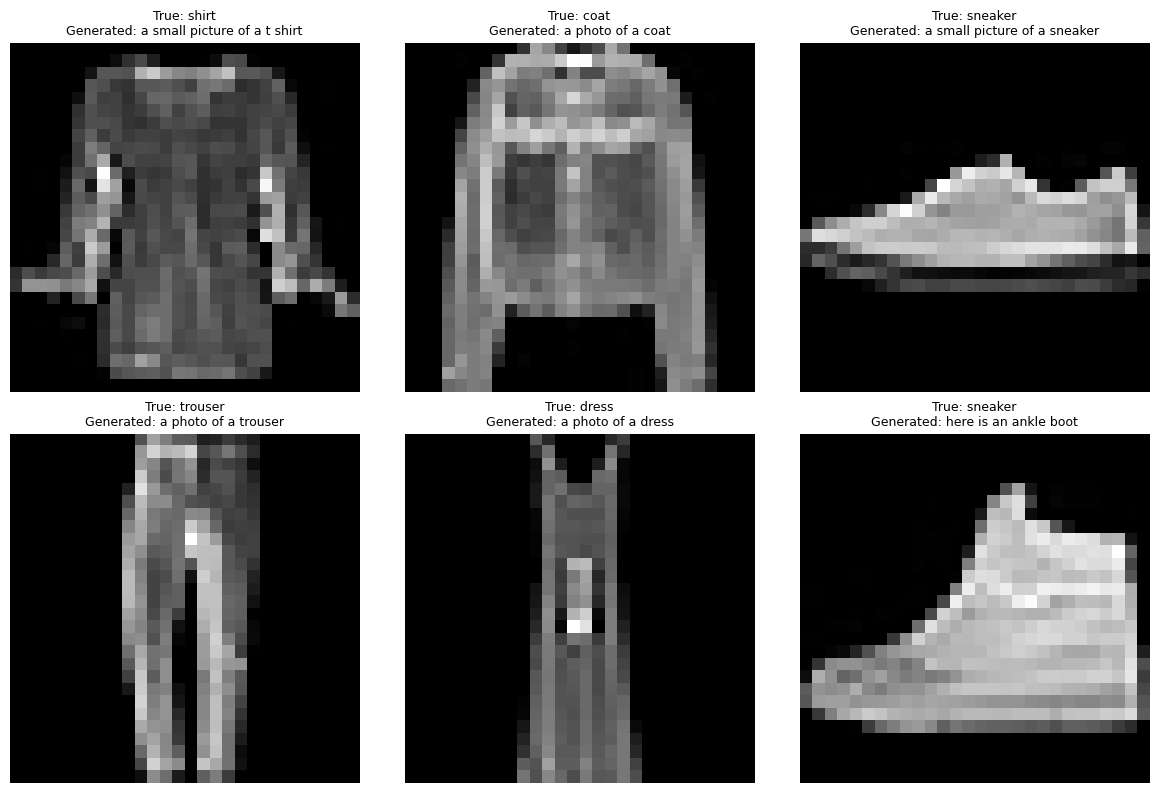


Saved plots: caption_training_loss.png, caption_predictions.png
Example generated caption: a small picture of a shirt


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
sample_indices = np.random.choice(len(test_images), 6, replace=False)
for ax, idx in zip(axes.ravel(), sample_indices):
    img = test_images[idx]
    true_label = class_names[int(y_test[test_idx[idx]])]
    pred_caption = generate_caption(img)
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"True: {true_label}\nGenerated: {pred_caption}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("caption_predictions.png")
plt.show()
plt.close()

print("\nSaved plots: caption_training_loss.png, caption_predictions.png")
print("Example generated caption:", generate_caption(test_images[0]))